# 09 - Department handovers

Which departments handle patients, who hands over to whom, and what the repeated ward records really are.

The log records the **department** (`org:group`) for each step. The codes are anonymised (A, B, C, ...), so each department's **role** is inferred from the steps it records (for example, a department that only records blood tests is shown as *Laboratory*). Roles are an interpretation, not official names.

A **handover** is two consecutive events of one patient recorded by different departments.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent
sys.path.append(str(ROOT / 'src'))

from conformance import load_log
from handover import (department_table, department_nodes, first_ward_department, handover_events, handover_pairs,
                      network_dot, role_nodes, save_network_png, summary, ward_transfers)
from plot_style import apply_style, save_fig, BLUE, INK, INK_SECONDARY

apply_style()
log = load_log()
departments = department_table(log)
handovers = handover_events(log)
roles = departments.set_index('department')['role']
stats = summary(log)
print(f"{stats['departments']} departments, {stats['events']:,} events, {stats['handovers']:,} handovers")

26 departments, 14,214 events, 6,642 handovers


## 1. Who does what?
Events per department with the inferred role.

In [2]:
by_role = departments.groupby('role').agg(departments=('department', 'nunique'), events=('events', 'sum'), codes=('department', lambda s: ', '.join(s)))
by_role['share_of_events_%'] = (by_role['events'] / by_role['events'].sum() * 100).round(1)
by_role.sort_values('events', ascending=False)

,departments,events,codes,share_of_events_%
role,,,,
Laboratory,1,7507,B,52.8
ER team,2,3477,"A, L",24.5
Ward,20,1215,"F, O, G, I, M, Q, R, P, H, W, N, D, T, S, J, V...",8.5
Triage,1,998,C,7.0
Discharge,1,739,E,5.2
Return (unit not recorded),1,278,?,2.0


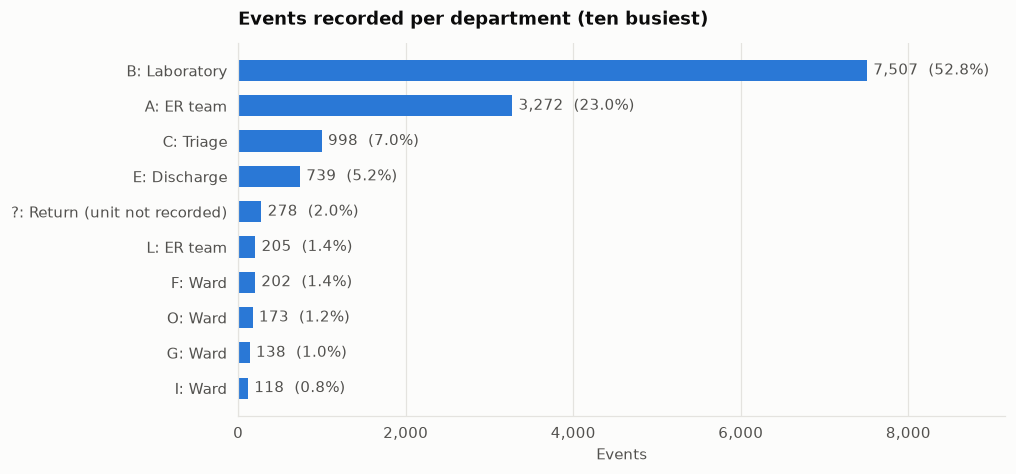

In [3]:
top = departments.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(top['label'], top['events'], color=BLUE, height=0.6)
ax.grid(axis='y', visible=False)
for i, (e, p) in enumerate(zip(top['events'], top['share_of_events_pct'])):
    ax.text(e + top['events'].max() * 0.01, i, f'{e:,}  ({p:.1f}%)', va='center', color=INK_SECONDARY, fontsize=10)
ax.set_xlim(0, top['events'].max() * 1.22)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
ax.set_title('Events recorded per department (ten busiest)')
ax.set_xlabel('Events')
save_fig(fig, 'handover_workload')
plt.show()

## 2. The handover network
Boxes are roles (colour = role), arrows are handovers between them, and the number is how many times. The loop on *Ward* is patients moving from one ward unit to another.

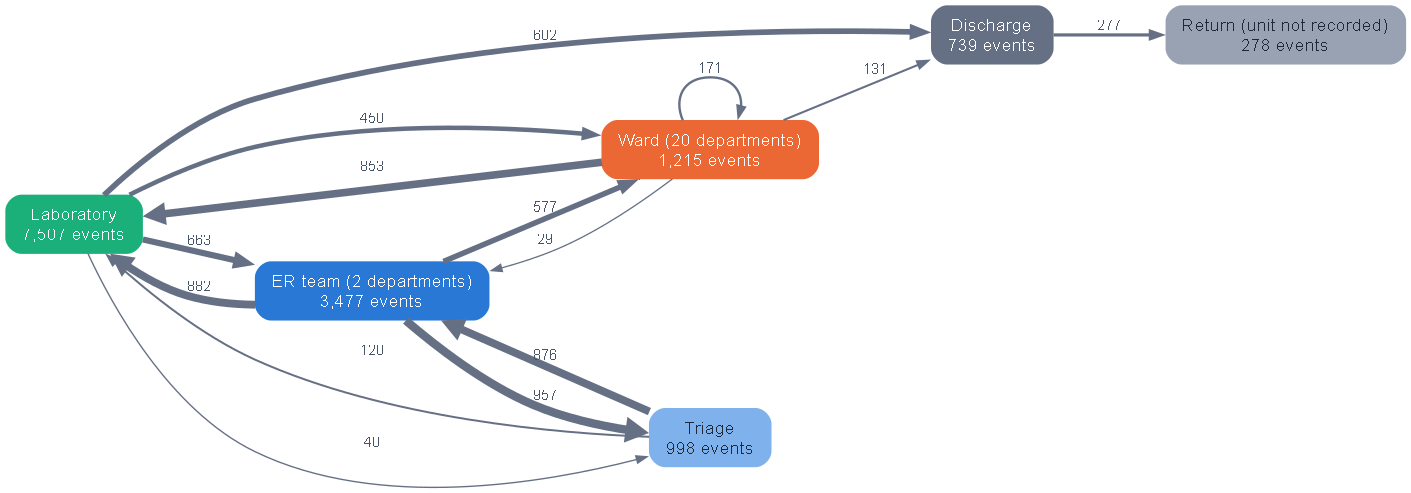

In [4]:
role_pairs = handover_pairs(handovers, roles)
dot = network_dot(role_pairs, role_nodes(departments), min_handovers=20)
save_network_png(dot, ROOT / 'reports' / 'figures' / 'handover_network.png')
display(Image(ROOT / 'reports' / 'figures' / 'handover_network.png', width=900))

In [5]:
role_pairs.head(10).assign(share=lambda d: d['share_of_handovers_pct'].round(1))[['from_department', 'to_department', 'handovers', 'share', 'median_wait_hours']].rename(columns={'from_department': 'from role', 'to_department': 'to role', 'median_wait_hours': 'median wait (h)'}).round(2)

,from role,to role,handovers,share,median wait (h)
0,ER team,Triage,957,14.4,0.13
1,ER team,Laboratory,882,13.3,0.21
2,Triage,ER team,876,13.2,0.01
3,Ward,Laboratory,853,12.8,20.50
4,Laboratory,ER team,663,10.0,1.48
5,Laboratory,Discharge,602,9.1,32.38
6,ER team,Ward,577,8.7,0.24
7,Laboratory,Ward,450,6.8,4.00
8,Discharge,Return (unit not recorded),277,4.2,1126.18
9,Ward,Ward,171,2.6,13.62


## 3. What are the repeated ward records?
Earlier analysis found 356 repeated `Admission NC` records. Here we check whether the department changes between one record and the next.

356 repeated ward records: 317 (89%) are recorded by a DIFFERENT department than the previous record; 39 by the same one.
Median time between the two records when the department changes: 18.0 hours


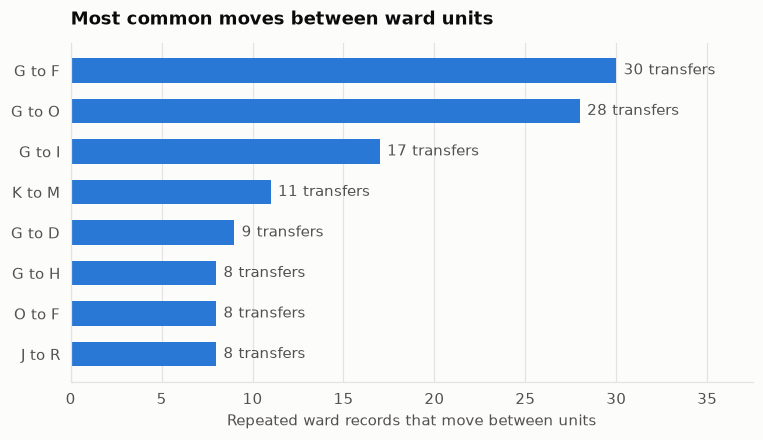

In [6]:
transfers = ward_transfers(log)
changed = transfers['changed_department']
print(f"{len(transfers)} repeated ward records: {int(changed.sum())} ({changed.mean() * 100:.0f}%) are recorded by a DIFFERENT department than the previous record; {int((~changed).sum())} by the same one.")
print(f"Median time between the two records when the department changes: {transfers.loc[changed, 'gap_hours'].median():.1f} hours")

moves = (transfers[changed].groupby(['previous_department', 'department']).size().rename('transfers').reset_index()
         .sort_values('transfers', ascending=False).head(8))
moves['route'] = moves['previous_department'] + ' to ' + moves['department']
plot = moves.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(plot['route'], plot['transfers'], color=BLUE, height=0.6)
ax.grid(axis='y', visible=False)
for i, v in enumerate(plot['transfers']):
    ax.text(v + 0.4, i, f'{v} transfers', va='center', color=INK_SECONDARY, fontsize=10)
ax.set_xlim(0, plot['transfers'].max() * 1.25)
ax.set_title('Most common moves between ward units')
ax.set_xlabel('Repeated ward records that move between units')
save_fig(fig, 'handover_ward_moves')
plt.show()

In [7]:
first_unit = first_ward_department(log).value_counts()
g_out = transfers[(transfers['previous_department'] == 'G') & changed]
pd.Series({
    'Patients whose first ward record is from unit G': int(first_unit.get('G', 0)),
    'Moves out of unit G to another unit': len(g_out),
    'Median hours between the G record and the next unit': round(g_out['gap_hours'].median(), 1),
    'Ward units seen': int((departments['role'] == 'Ward').sum()),
}, name='value').to_frame()

,value
Patients whose first ward record is from unit G,137.0
Moves out of unit G to another unit,121.0
Median hours between the G record and the next unit,16.6
Ward units seen,20.0


## 4. Where is the slowest handover?
Handovers between departments (frequent pairs only). The wait is the time between the two consecutive events.

In [8]:
pairs = handover_pairs(handovers)
slow = pairs[pairs['handovers'] >= 30].sort_values('median_wait_hours', ascending=False).head(8)
slow.assign(median_wait_hours=slow['median_wait_hours'].round(1), p90_wait_hours=slow['p90_wait_hours'].round(1))[['from_department', 'to_department', 'handovers', 'median_wait_hours', 'p90_wait_hours']].rename(columns={'from_department': 'from', 'to_department': 'to', 'median_wait_hours': 'median wait (h)', 'p90_wait_hours': '90th pct (h)'})

,from,to,handovers,median wait (h),90th pct (h)
5,E,?,277,1126.2,5101.0
6,F,B,156,35.6,64.9
15,M,B,65,35.0,80.6
7,O,B,139,32.8,67.2
4,B,E,602,32.4,102.0
27,R,B,36,30.0,71.3
10,I,B,83,25.2,70.1
26,D,B,37,21.0,67.0


## Findings
- **The work is concentrated in a few departments.** The 26 departments include one laboratory (B), which records 53% of all events (the blood tests), two ER teams (A and L) with 24.5%, one triage desk (C) with 7%, one discharge department (E) with 5%, and 20 ward units that together record 8.5%. The roles are inferred from the steps each department records.
- **Handovers are constant.** 6,642 handovers happen, which is half of all step-to-step transitions. The biggest flows are between the ER team and triage (957 and 876), and between the ER team and the laboratory (882 and 663).
- **Repeated ward records are mostly transfers between ward units, not duplicate entries.** 317 of the 356 repeated ward admission records (89%) are recorded by a different department than the previous record, and only 39 by the same one. This answers the earlier question about why ward admission repeats.
- **One unit is the entry point.** For 137 patients the first ward record comes from unit G, and 121 of its records are followed by a record from another unit (mainly F, O and I) a median of 16.6 hours later. That G is an admission or holding unit is an interpretation, because the department codes are anonymised.
- **Possible discharge delay.** After the last laboratory record, a median of 32 hours (90th percentile 102 hours) passes before the discharge is recorded, for 602 patients. The data cannot show whether this is clinical or administrative.
- **Ward-to-laboratory waits reflect testing rhythm.** Waits of 20 to 36 hours between a ward record and the next laboratory record match routine monitoring, not delays.
- **Limits.** Department codes are anonymised, so roles and the "entry unit" reading are interpretations to confirm with the mentor.
- **Next step:** add these analyses to the dashboard.
